# Imports

In [38]:
# Get imports and functions needed
%run BaseFiles/Imports.ipynb
%run BaseFiles/Functions.ipynb

# Set global variables
colour1 = "royalblue"
colour2 = "red"
colour3 = "goldenrod"

# CME Buffer
CMEBuffer = 6

# Read data from files

In [39]:
# Places to get and save files
DataDirectory = "Data/windData/"
dataName = "wind_min_b"
PlotDirectory = "Plots/WindYearlyPlots/"

# Details: Yearly, minutely data, bow-shock shifted

In [40]:
# Variables
DataSource = "Wind"

TimeFrames = [["1996-01-01 00:00","1996-02-01 00:00"], ["1996-1-01 00:00", "1997-01-01 00:00"], ["2001-01-01 00:00", "2002-01-01 00:00"] ] # Basic, Maximum, Minimum
# Basic
# # Start  = "1996-01-01 00:00"
# # End = "1996-02-01 00:00"
# Minimum
# # Start  = "1996-06-01 00:00"
# # End = "1996-07-01 00:00"
# Maximum
# # Start  = "2001-06-01 00:00"
# # End = "2001-12-01 00:00"



# Read data to dataframes

In [41]:
dataTimeSerieses = [[],[],[]] # empty array for data

for j in range(len(TimeFrames)):
    Start = TimeFrames[j][0]
    End = TimeFrames[j][1]
    #Separated by data source as files may have different file name conventions
    if DataSource == "Wind": # If WIND data
        YearlyRange = Yearly(Start, End, frequency = 'MS') #Get range of dates needed # changed to monthly
        print(YearlyRange)
        # dataTimeSerieses = [] # empty array for data
        # StartAndEnd = [] # empty array for start and end times
        for i in range(len(YearlyRange)-1): # for each date range in time range needed
            StartDate = YearlyRange[i] # first file in range
            if YearlyRange[i][4:6] == "01" or YearlyRange[i][4:6] == "03" or YearlyRange[i][4:6] == "05" or YearlyRange[i][4:6] == "07" or YearlyRange[i][4:6] == "08" or YearlyRange[i][4:6] == "10" or YearlyRange[i][4:6] == "12":
                EndDate = YearlyRange[i][0:6] + "31" # last file in range
            elif YearlyRange[i][4:6] == "02":
                if YearlyRange[i][0:4] == "2000" or YearlyRange[i][0:4] == "2008" or YearlyRange[i][0:4] == "2016" or YearlyRange[i][0:4] == "2024":
                    EndDate = YearlyRange[i][0:6] + "29" # last file in range
                else:
                    EndDate = YearlyRange[i][0:6] + "28" # last file in range
            elif YearlyRange[i][4:6] == "04" or YearlyRange[i][4:6] == "06" or YearlyRange[i][4:6] == "09" or YearlyRange[i][4:6] == "11":
                EndDate = YearlyRange[i][0:6] + "30" # last file in range            
            # print(StartDate, EndDate)
            # DateRange = ReadDates(StartDate, EndDate) # get date range
            dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
            dataTS = dfToSeries(dataFound) # convert to timeseries
            dataTS = AddTotVsw(dataTS) # add totvsw
            dataTS = AddBMag(dataTS) # add bmag
            # dataTS = AddLogBMag(dataTS) 
            # dataTS = AddLogBX(dataTS)
            dataTimeSerieses[j].append(dataTS) # add to data array
            # StartAndEnd.append([StartDate, EndDate]) # add start and end dates to times array

    else: # if not wind (or other coded sources)
        print("Data source not known") # give error message


['19960101', '19960201']
['19960101', '19960201', '19960301', '19960401', '19960501', '19960601', '19960701', '19960801', '19960901', '19961001', '19961101', '19961201', '19970101']
['20010101', '20010201', '20010301', '20010401', '20010501', '20010601', '20010701', '20010801', '20010901', '20011001', '20011101', '20011201', '20020101']


In [42]:
# print(dataTimeSerieses)
# print(len(dataTimeSerieses))
# print(dataTimeSerieses[2])

# combined_goes_ts = dataTimeSerieses[0].concatenate(dataTimeSerieses[1])


In [43]:
def resampleMean(data, rate, label = "right"):
    resampled = data.resample(rate, label=label).mean()
    resampledTS = TimeSeries(resampled)
    return resampledTS

In [44]:
# print(dataTimeSerieses[1][1])
for i in range(len(dataTimeSerieses)):
    # print(i)
    for j in range(len(dataTimeSerieses[i])):
        # print(j)
        dataTimeSerieses[i][0] = dataTimeSerieses[i][0].concatenate(dataTimeSerieses[i][j])
    
    # print(dataTimeSerieses[i][0])

dataTSConcat = [dataTimeSerieses[0][0], dataTimeSerieses[1][0], dataTimeSerieses[2][0]]


# Remove CMEs

## Get CME start and end dates

In [45]:
from datetime import datetime
from datetime import date, timedelta
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np 

import pandas as pd
url='https://helioforecast.space/static/sync/icmecat/HELIO4CAST_ICMECAT_v23.csv'
ic=pd.read_csv(url)
ic.keys()

ic = ic.truncate(before=0, after=1901) # get from current most recent (2025-08-10) back to beginning of 1996



## Only Wind ICMEs

In [46]:
WindOnly = ic.loc[ic['sc_insitu'] == "Wind"]   # create a wind only dataframe
WindOnly.insert(0, "Index", range(0, len(WindOnly.icme_start_time)))   # set the indexes to be 0,1,2,3, etc. instead of the original event indexes
WindOnly.set_index("Index", inplace = True)

print(WindOnly.icme_start_time)
print(WindOnly.sc_insitu)

Index
0      2025-07-26T16:44Z
1      2025-07-03T04:52Z
2      2025-06-12T19:34Z
3      2025-06-07T00:12Z
4      2025-06-04T13:44Z
             ...        
535    1996-07-01T13:05Z
536    1996-05-27T14:45Z
537    1996-05-16T22:47Z
538    1996-04-04T11:59Z
539    1996-02-15T15:07Z
Name: icme_start_time, Length: 540, dtype: str
Index
0      Wind
1      Wind
2      Wind
3      Wind
4      Wind
       ... 
535    Wind
536    Wind
537    Wind
538    Wind
539    Wind
Name: sc_insitu, Length: 540, dtype: str


## Get start and end dates

In [47]:
print(WindOnly.icme_start_time)

ICMETimes = []
for i in range(len(WindOnly.icme_start_time)):
    StartTime = datetime.fromisoformat(WindOnly.icme_start_time[i])-timedelta(hours=CMEBuffer)
    # print(datetime.fromisoformat(WindOnly.icme_start_time[i]))
    # print(StartTime)
    EndTime = datetime.fromisoformat(WindOnly.mo_end_time[i])+timedelta(hours=CMEBuffer)
    ICMETimes.append([StartTime.replace(tzinfo=None), EndTime.replace(tzinfo=None)])

print(ICMETimes[:])

# dt = ICMETimes[0][].replace(tzinfo=None)
# print(dt)

Index
0      2025-07-26T16:44Z
1      2025-07-03T04:52Z
2      2025-06-12T19:34Z
3      2025-06-07T00:12Z
4      2025-06-04T13:44Z
             ...        
535    1996-07-01T13:05Z
536    1996-05-27T14:45Z
537    1996-05-16T22:47Z
538    1996-04-04T11:59Z
539    1996-02-15T15:07Z
Name: icme_start_time, Length: 540, dtype: str
[[datetime.datetime(2025, 7, 26, 10, 44), datetime.datetime(2025, 7, 27, 23, 40)], [datetime.datetime(2025, 7, 2, 22, 52), datetime.datetime(2025, 7, 5, 1, 6)], [datetime.datetime(2025, 6, 12, 13, 34), datetime.datetime(2025, 6, 13, 12, 2)], [datetime.datetime(2025, 6, 6, 18, 12), datetime.datetime(2025, 6, 8, 15, 28)], [datetime.datetime(2025, 6, 4, 7, 44), datetime.datetime(2025, 6, 5, 10, 38)], [datetime.datetime(2025, 6, 2, 14, 0), datetime.datetime(2025, 6, 3, 20, 52)], [datetime.datetime(2025, 6, 1, 21, 56), datetime.datetime(2025, 6, 2, 14, 4)], [datetime.datetime(2025, 6, 1, 12, 54), datetime.datetime(2025, 6, 2, 6, 32)], [datetime.datetime(2025, 6, 1, 6, 

##  Number of hours of data that CMEs will be responsible for removing

In [48]:
# print(ICMETimes)

AllTimesHours = [] # empty array for times between each start and end of CMEs (includes buffer either side of the CME/MO start/end times)
for i in range(len(ICMETimes)): # for each ICME
    timespan = (ICMETimes[i][1]-ICMETimes[i][0]).total_seconds() # get the time removed in seconds
    AllTimesHours.append(timespan/3600) # add the times in hours to the array

print(AllTimesHours) # print the array
sum(AllTimesHours) # sum the array

print("Time in hours removed by CME removal (times for all CMEs seen by wind + 24 hours \ntotal buffer time, does not account for data gaps already existing in the data \nduring CMEs.): " + str(sum(AllTimesHours)) + " hours.")

[36.93333333333333, 50.233333333333334, 22.466666666666665, 45.266666666666666, 26.9, 30.866666666666667, 16.133333333333333, 17.633333333333333, 18.7, 18.733333333333334, 34.06666666666667, 32.03333333333333, 39.13333333333333, 42.03333333333333, 43.166666666666664, 29.033333333333335, 24.766666666666666, 21.866666666666667, 21.8, 30.6, 26.9, 24.566666666666666, 24.966666666666665, 25.833333333333332, 21.533333333333335, 29.95, 31.366666666666667, 22.566666666666666, 20.733333333333334, 29.8, 25.033333333333335, 27.8, 17.266666666666666, 33.1, 68.5, 31.1, 90.4, 20.1, 19.6, 29.366666666666667, 42.833333333333336, 31.266666666666666, 37.1, 36.266666666666666, 44.5, 19.7, 23.833333333333332, 28.166666666666668, 18.966666666666665, 34.766666666666666, 15.833333333333334, 13.933333333333334, 19.416666666666668, 15.683333333333334, 17.45, 51.233333333333334, 41.53333333333333, 48.1, 19.666666666666668, 23.666666666666668, 31.833333333333332, 39.03333333333333, 50.5, 53.86666666666667, 34.5,

### For minimum year 1996

In [49]:
# For minimum year 1996
# print(len(ICMETimes))
print(ICMETimes[532:540])
ICMETimes1996 = ICMETimes[532:540] # 8 CMEs
print(len(ICMETimes1996))

TimesMin = [] # empty array for times between each start and end of CMEs (includes buffer either side of the CME/MO start/end times)
for i in range(len(ICMETimes1996)): # for each ICME
    timespanMin = (ICMETimes1996[i][1]-ICMETimes1996[i][0]).total_seconds() # get the time removed in seconds
    TimesMin.append(timespanMin/3600) # add the times in hours to the array

print(TimesMin) # print the array
sum(TimesMin) # sum the array
# print(sum(Times)/len(ICMETimes1996))

TotalTimeRemovedByCMEsMin = sum(TimesMin)

print("1996: Time in hours removed by CME removal (times for all CMEs seen by wind + 24 hours \ntotal buffer time, does not account for data gaps already existing in the data \nduring CMEs.): " + str(TotalTimeRemovedByCMEsMin) + " hours.")

[[datetime.datetime(1996, 12, 23, 19, 26), datetime.datetime(1996, 12, 25, 17, 44)], [datetime.datetime(1996, 8, 7, 2, 23), datetime.datetime(1996, 8, 8, 19, 12)], [datetime.datetime(1996, 7, 2, 10, 4), datetime.datetime(1996, 7, 3, 4, 47)], [datetime.datetime(1996, 7, 1, 7, 5), datetime.datetime(1996, 7, 2, 16, 17)], [datetime.datetime(1996, 5, 27, 8, 45), datetime.datetime(1996, 5, 29, 8, 22)], [datetime.datetime(1996, 5, 16, 16, 47), datetime.datetime(1996, 5, 17, 17, 58)], [datetime.datetime(1996, 4, 4, 5, 59), datetime.datetime(1996, 4, 5, 3, 36)], [datetime.datetime(1996, 2, 15, 9, 7), datetime.datetime(1996, 2, 16, 14, 59)]]
8
[46.3, 40.81666666666667, 18.716666666666665, 33.2, 47.61666666666667, 25.183333333333334, 21.616666666666667, 29.866666666666667]
1996: Time in hours removed by CME removal (times for all CMEs seen by wind + 24 hours 
total buffer time, does not account for data gaps already existing in the data 
during CMEs.): 263.31666666666666 hours.


### For maximum year 2001

In [50]:
# For maximum year 2001
# print(len(ICMETimes))
print(ICMETimes[411:434])
ICMETimes2001 = ICMETimes[411:434] # 23 CMEs
print(len(ICMETimes2001))

TimesMax = [] # empty array for times between each start and end of CMEs (includes buffer either side of the CME/MO start/end times)
for i in range(len(ICMETimes2001)): # for each ICME
    timespanMax = (ICMETimes2001[i][1]-ICMETimes2001[i][0]).total_seconds() # get the time removed in seconds
    TimesMax.append(timespanMax/3600) # add the times in hours to the array

print(TimesMax) # print the array
sum(TimesMax) # sum the array
# print(sum(Times)/len(ICMETimes2001))
TotalTimeRemovedByCMEsMax = sum(TimesMax)

print("2001: Time in hours removed by CME removal (times for all CMEs seen by wind + 24 hours \ntotal buffer time, does not account for data gaps already existing in the data \nduring CMEs.): " + str(TotalTimeRemovedByCMEsMax) + " hours.")

[[datetime.datetime(2001, 12, 30, 14, 5), datetime.datetime(2001, 12, 31, 13, 46)], [datetime.datetime(2001, 12, 28, 23, 16), datetime.datetime(2001, 12, 31, 1, 10)], [datetime.datetime(2001, 11, 23, 23, 51), datetime.datetime(2001, 11, 25, 19, 17)], [datetime.datetime(2001, 10, 31, 7, 46), datetime.datetime(2001, 11, 2, 10, 47)], [datetime.datetime(2001, 10, 27, 21, 13), datetime.datetime(2001, 10, 30, 16, 47)], [datetime.datetime(2001, 10, 21, 10, 39), datetime.datetime(2001, 10, 23, 6, 47)], [datetime.datetime(2001, 9, 30, 13, 14), datetime.datetime(2001, 10, 2, 3, 34)], [datetime.datetime(2001, 9, 29, 3, 28), datetime.datetime(2001, 10, 1, 1, 14)], [datetime.datetime(2001, 9, 25, 14, 16), datetime.datetime(2001, 9, 26, 22, 47)], [datetime.datetime(2001, 8, 17, 5, 1), datetime.datetime(2001, 8, 19, 1, 12)], [datetime.datetime(2001, 8, 5, 6, 28), datetime.datetime(2001, 8, 7, 5, 59)], [datetime.datetime(2001, 6, 26, 23, 59), datetime.datetime(2001, 6, 29, 8, 23)], [datetime.datetime(

In [51]:
len(dataTSConcat[1].to_dataframe())

525290

## Remove the dates from the data

In [52]:
dataTSConcatNoCMEs = []
dataTSConcatOnlyCMEs = []
for i in range(len(dataTSConcat)):                              # for each dataset
    # print(len(dataTimeSerieses[i].to_dataframe()[i]))
    print(i)
    INDEX = np.ones(len(dataTSConcat[i].to_dataframe()))        # get ones array for tracking where CMEs are
    # INDEX = np.ones(len(dataTimeSerieses[i].to_dataframe()))
    for CME in ICMETimes:                                           # for each CME in the catalogue seen by Wind
        start = CME[0]                                              # get start time
        end = CME[1]                                                # get end time
        # print(start, end)
        ind = (dataTSConcat[i].to_dataframe().index < start) | (dataTSConcat[i].to_dataframe().index > end) # get 0 as an index for times that CME is present, get 1 for times it is not present
        # ind = np.where((dataTimeSerieses[0].to_dataframe().index < start) | (dataTimeSerieses[0].to_dataframe().index > end))
        # dfCMEsRemoved.where((dfCMEsRemoved.index > start) | (dfCMEsRemoved.index < end))
        # ind = dataTimeSerieses[0].to_dataframe().loc[(dataTimeSerieses[0].to_dataframe().index < start) & (dataTimeSerieses[0].to_dataframe().index > end)]
        # print(ind)
        # print(len(ind))
        INDEX = INDEX * ind                                         # Multiply the tracking array by the array for this CME s.t. the resulting array gets 0's for any times with CMEs and 1's for times without CMEs
    MapForINDEX = INDEX.astype(np.bool)                             # Change the 0/1 array to False/True
    dfCMEsRemoved = dataTSConcat[i].to_dataframe()[MapForINDEX] # Make a new year dataframe where the CMEs are removed
    # print(dfCMEsRemoved[64975:65000])
    dfCMEsRemoved = dfToSeries(dfCMEsRemoved)                                       # Make the data frame into a time series
    dataTSConcatNoCMEs.append(dfCMEsRemoved)                    # Amend the new Serieses array with the CME removed versions

    dfOnlyCMEs = dataTSConcat[i].to_dataframe()[~MapForINDEX] # Make a new year dataframe where the CMEs are present
    # print(dfCMEsRemoved[64975:65000])
    dfOnlyCMEs = dfToSeries(dfOnlyCMEs)                                       # Make the data frame into a time series
    dataTSConcatOnlyCMEs.append(dfOnlyCMEs)                    # Amend the new Serieses array with the CME present versions

print(dataTSConcatNoCMEs[0])
print(dataTSConcatNoCMEs[1])
print(dataTSConcatNoCMEs[2])

# print(dataTSConcatOnlyCMEs[0])

# print(len(ind[0]))
# print(index)
# #############
# #Separated by data source as files may have different file name conventions
# if DataSource == "Wind":
#     YearlyRange = Yearly(Start, End)
#     # print(YearlyRange)
#     dataTimeSerieses = []
#     StartAndEnd = []
#     for i in range(len(YearlyRange)-1):
#         StartDate = YearlyRange[i]
#         EndDate = YearlyRange[i][0:4] + "1231"
#         # print(StartDate, EndDate)
#         # DateRange = ReadDates(StartDate, EndDate) # get date range
#         dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
#         dataTS = dfToSeries(dataFound)
#         dataTS = AddTotVsw(dataTS) # add totvsw
#         dataTS = AddBMag(dataTS) # add bmag
#         dataTS = AddLogBMag(dataTS) 
#         dataTS = AddLogBX(dataTS)
#         dataTimeSerieses.append(dataTS)
#         StartAndEnd.append([StartDate, EndDate])

# else:
#     print("Data source not known")

#     # print(dataTimeSerieses)
#     # print(StartAndEnd)
# ##############

# # # Filter data between two dates
# filtered_df = df.loc[(df['date'] >= '2020-09-01')
#                      & (df['date'] < '2020-09-15')]

# print(len(INDEX))
# print(len(dataTimeSerieses[0].to_dataframe()))
# print(INDEX[524500:])
# print(np.unique(INDEX))

# MapForINDEX = INDEX.astype(np.bool)
# dfCMEsRemoved =  dataTimeSerieses[0].to_dataframe()[MapForINDEX]
# print(dfCMEsRemoved[64975:65000])


0
1
2
SunPy TimeSeries
----------------
Observatory:			Unknown
Instrument:			Unknown
Channel(s):			Year<br>DOY<br>Hour<br>Minute<br>IMF_PTS<br>PercentInterp<br>CP/MVFlag<br>Timeshift<br>PFN_XGSE<br>PFN_YGSE<br>PFN_ZGSE<br>ScalarB<br>Bx_GSEGSM<br>ByGSE<br>BzGSE<br>ByGSM<br>BzGSM<br>RMSTimeshift<br>RMS_PFN<br>RMSScalarB<br>RMSFieldVector<br>Plasma_PTS<br>FlowSpeed<br>Vx_GSE<br>Vy_GSE<br>Vz_GSE<br>ProtonDensity<br>Temp<br>X_s_c_GSE<br>Y_s_c_GSE<br>Z_s_c_GSE<br>X_targ_GSE<br>Y_targ_GSE<br>Z_targ_GSE<br>RMS_targ<br>DBOT1<br>DBOT2<br>TotVsw<br>BMag
Start Date:			1996-01-01 00:00:00
End Date:			1996-01-31 23:59:00
Center Date:			1996-01-16 11:59:30
Resolution:			59.999 s
Samples per Channel:		44640
Data Range(s):		Year             0.00E+00<br>DOY              3.00E+01<br>Hour             2.30E+01<br>Minute           5.90E+01<br>IMF_PTS          7.80E+01<br>PercentInterp    1.00E+02<br>CP/MVFlag        1.00E+00<br>Timeshift        6.36E+03<br>PFN_XGSE         8.90E-01<br>PFN_YGSE         1.92E

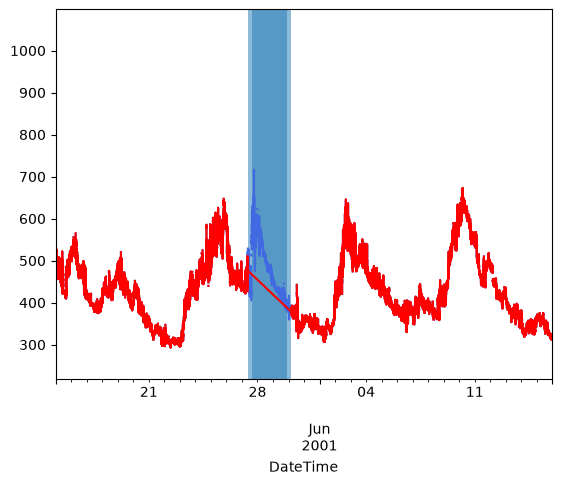

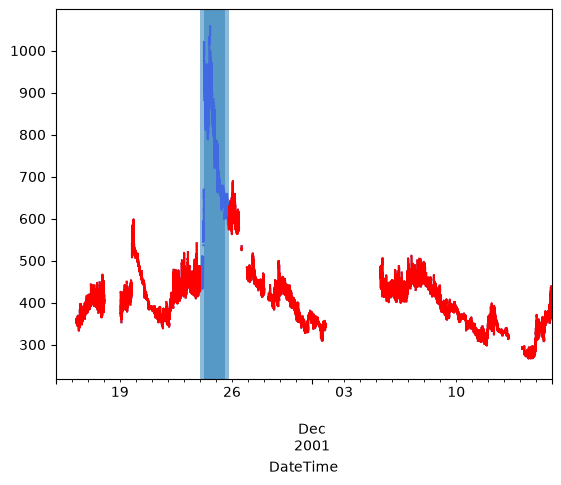

In [53]:
ds = dataTSConcat[2]
dsnc = dataTSConcatNoCMEs[2]
# dsoc = dataTimeSeriesesOnlyCMEs[21]
# CMEStart =  '2001-11-24 05:51' # [0] cme start time 2001-11-24 05:51
# CMEEnd = '2001-11-25 13:17' # mo end time 2001-11-25 13:17
# CMEStart =  '2001-10-31 13:46' # [0] cme start time 2001-10-31 13:46
# CMEEnd = '2001-11-02 04:47' # mo end time 2001-11-02 04:47
# CMEStart =  '2001-09-29 09:28' # [0] cme start time 2001-09-29 09:28
# CMEEnd = '2001-09-30 19:14' # mo end time 2001-09-30 19:14

ylim = [300,1000]

Alpha2 = 1
# ds.to_dataframe()["TotVsw"][350000:400000].plot(color = "royalblue", alpha=Alpha2)
# dsnc.to_dataframe()["TotVsw"][350000:400000].plot( color="red", alpha=Alpha2)
ds.to_dataframe()["TotVsw"].plot(color = "royalblue", alpha=Alpha2)
dsnc.to_dataframe()["TotVsw"].plot( color="red", alpha=Alpha2)
plt.xlim(['2001-05-15 00:00', '2001-06-15 23:00'])

plt.axvspan('2001-05-27 14:45', '2001-05-29 21:34', alpha=0.5) # start and end
plt.axvspan('2001-05-27 08:45', '2001-05-30 03:34', alpha=0.5) # buffer of 6 hours
plt.show()

# CMEStart =  '2001-11-24 05:51' # [0] cme start time 2001-11-24 05:51
# CMEEnd = '2001-11-25 13:17' # mo end time 2001-11-25 13:17
ds.to_dataframe()["TotVsw"].plot(color = "royalblue", alpha=Alpha2)
dsnc.to_dataframe()["TotVsw"].plot( color="red", alpha=Alpha2)
plt.xlim(['2001-11-15 00:00', '2001-12-15 23:00'])

plt.axvspan('2001-11-24 05:51', '2001-11-25 13:17', alpha=0.5) # start and end
plt.axvspan('2001-11-23 23:51', '2001-11-25 19:17', alpha=0.5) # buffer of 6 hours
plt.show()

# print("With CMEs")
# PlotVsw(TimeSeries(ds.truncate(CMEStart, CMEEnd)), XLim = [CMEStart, CMEEnd], Columns = ["TotVsw"], YLim = ylim)
# print("CMEs removed")
# PlotVsw(TimeSeries(dsnc.truncate(CMEStart, CMEEnd)), XLim = [CMEStart, CMEEnd], Columns = ["TotVsw"], YLim = ylim)
# print("Only CMEs")
# PlotVsw(TimeSeries(dsoc.truncate(CMEStart, CMEEnd)), XLim = [CMEStart, CMEEnd], Columns = ["TotVsw"], YLim = ylim)


In [17]:
# print(dataTSConcatNoCMEs[0])
# print(dataTSConcatNoCMEs[1])
# print(dataTSConcatNoCMEs[2])
dataTSConcat = [dataTSConcatNoCMEs[0], dataTSConcatNoCMEs[1], dataTSConcatNoCMEs[2]]

print(dataTSConcat[0].to_dataframe())
print(dataTSConcat[1].to_dataframe())
print(dataTSConcat[2].to_dataframe())


                     Year  DOY  Hour  Minute  IMF_PTS  PercentInterp  \
DateTime                                                               
1996-01-01 00:00:00  1996    1     0       0      2.0          100.0   
1996-01-01 00:01:00  1996    1     0       1      2.0          100.0   
1996-01-01 00:02:00  1996    1     0       2      1.0          100.0   
1996-01-01 00:03:00  1996    1     0       3      1.0          100.0   
1996-01-01 00:04:00  1996    1     0       4      1.0          100.0   
...                   ...  ...   ...     ...      ...            ...   
1996-01-31 23:55:00  1996   31    23      55      5.0            0.0   
1996-01-31 23:56:00  1996   31    23      56     12.0            0.0   
1996-01-31 23:57:00  1996   31    23      57     14.0            0.0   
1996-01-31 23:58:00  1996   31    23      58     12.0           17.0   
1996-01-31 23:59:00  1996   31    23      59      3.0          100.0   

                     CP/MVFlag  Timeshift  PFN_XGSE  PFN_YGSE  

In [18]:
x = dataTSConcat[2].to_dataframe()["TotVsw"]

In [19]:
x

DateTime
2001-01-01 00:00:00           NaN
2001-01-01 00:01:00           NaN
2001-01-01 00:02:00    279.095647
2001-01-01 00:03:00    279.820764
2001-01-01 00:04:00    280.296325
                          ...    
2001-12-31 23:55:00           NaN
2001-12-31 23:56:00           NaN
2001-12-31 23:57:00           NaN
2001-12-31 23:58:00           NaN
2001-12-31 23:59:00           NaN
Name: TotVsw, Length: 460539, dtype: float64

In [20]:
x.resample("400s").mean()

DateTime
2001-01-01 00:00:00    279.890212
2001-01-01 00:06:40    284.389587
2001-01-01 00:13:20    278.952088
2001-01-01 00:20:00    285.050028
2001-01-01 00:26:40    287.252549
                          ...    
2001-12-31 23:26:40    476.297329
2001-12-31 23:33:20           NaN
2001-12-31 23:40:00    484.669496
2001-12-31 23:46:40           NaN
2001-12-31 23:53:20           NaN
Freq: 400s, Name: TotVsw, Length: 78840, dtype: float64

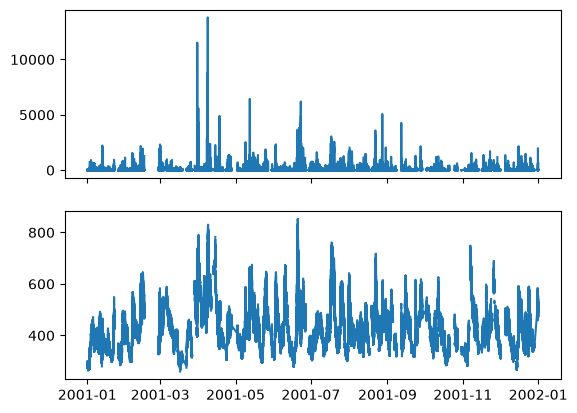

In [21]:
fig, ax = plt.subplots(2, sharex=True)
ax[1].plot(x)
ax[0].plot(x.resample("300s").var())

# Working on one month

Caption: (Top panel) Time series of TotVsw for January 1996 calculated from OMNI/Wind data with 1 minute cadence (blue). 
Data is resampled to have an hourlay cadence (red). (Bottom panels) Calculated hourly variance, difference between neighbouring points (hourly), 
and daily mean, median and standard deviation. Black horizontal lines show the regions of steadiness for this threshold.


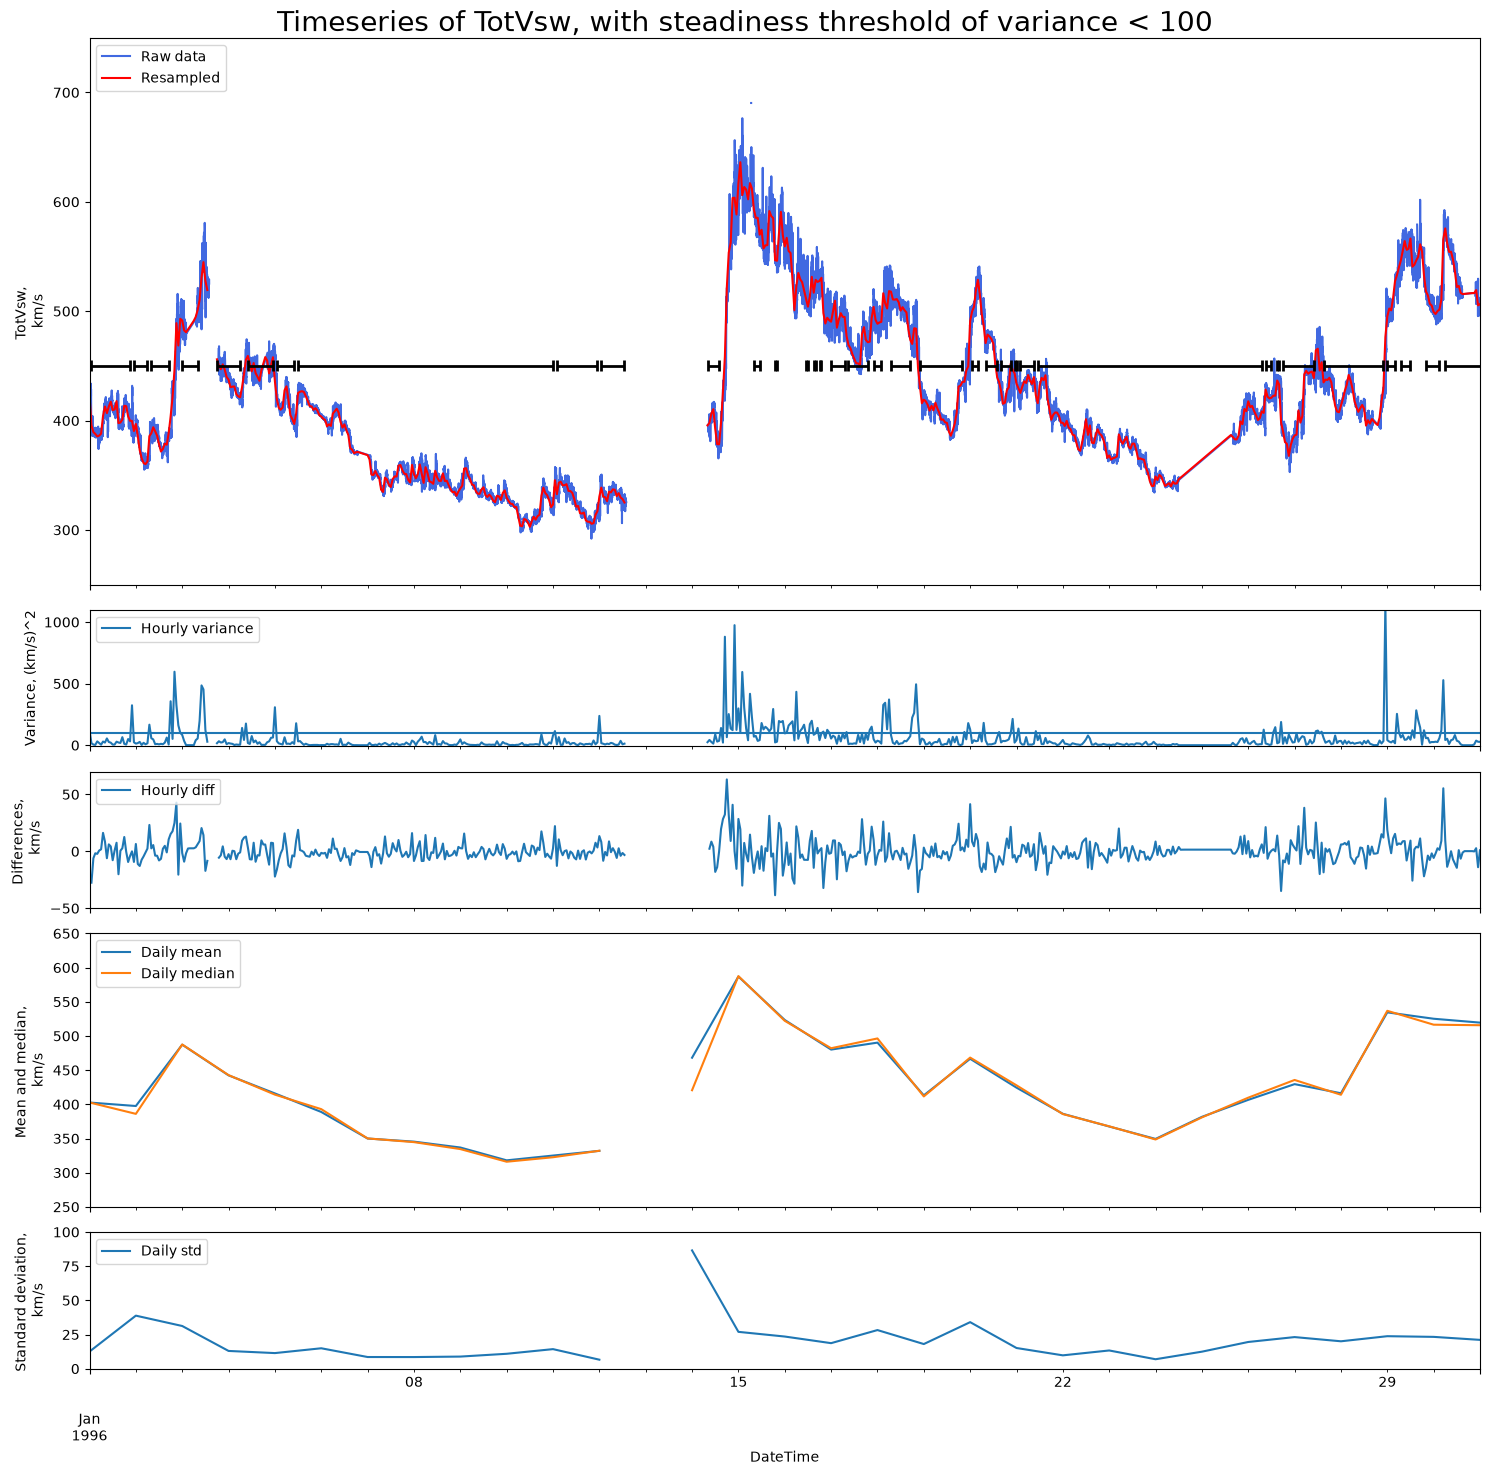

[20.0, 7.0, 9.0, 8.0, 12.0, 13.0, 9.0, 132.0, 21.0, 12.0, 6.0, 3.0, 1.0, 1.0, 1.0, 1.0, 7.0, 10.0, 4.0, 10.0, 22.0, 3.0, 6.0, 5.0, 1.0, 7.0, 116.0, 3.0, 1.0, 16.0, 31.0, 4.0, 5.0, 7.0, 20.0, 2.0, 3.0, 3.0, 4.0]


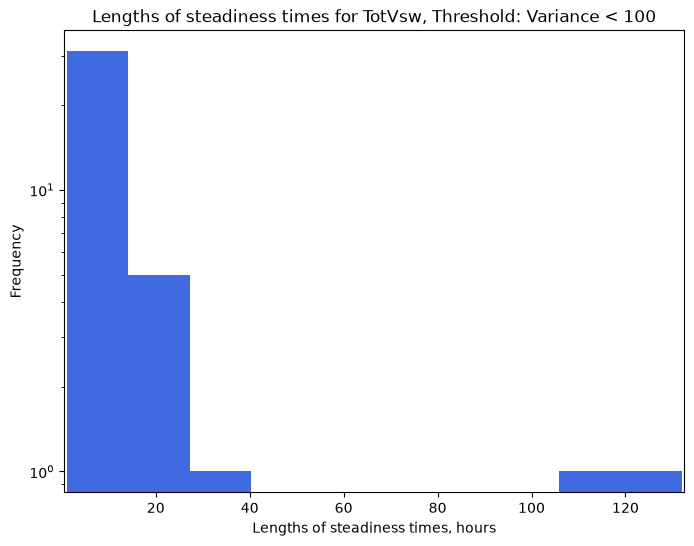

In [22]:
# TotVsw
Variable = "TotVsw"
Unit = "km/s"
# YLim = [[250, 750],[-50, 1100],[-50, 70], [250, 650], [0, 40]] # Hourly stats rates
YLim = [[250, 750],[-10, 1100],[-50, 70], [250, 650], [0, 100]] # Daily stats rates
Thres = 10**2

# # BMag
# Variable = "BMag"
# Unit = "nT"
# YLim = [[-1, 20],[-2, 10],[-5, 6], [0, 15], [0, 3]]
# Thres = 0.1

#Timeseries
resamplerate = "1h"

#Histograms
Bins = [1,2,3,4,5,6,7,8,9,10,11,12]
Histogram = (8,6)

fig, axs = plt.subplots(5,1, sharex=True, height_ratios=[4,1,1,2,1], figsize=(15, 15))
## raw data
# rawData = dataTSConcat[0].to_dataframe() 

## interpolated raw data, no restrictions
# rawData = dataTSConcat[0].to_dataframe().interpolate() # interpolated raw data

# ## interpolate only over certain timespans/ jumps

# Attempting to get the change to depend on var not y distance
# def interpolate_small_jumps(series, max_var, resample_rate): 
#     # resampled_series = series.resample(resamplerate).mean()
#     hourly_var = series.resample(resample_rate).var()
#     print(hourly_var)
#     before = hourly_var.ffill()
#     after = hourly_var.bfill()
#     print(before, after)
#     hourly_var = series.resample(resample_rate).var()
#     fill_allowed = series.isna() & ((after - before).abs() < max_var)
#     interpolated = series.interpolate(method="time")
#     return series.where(~fill_allowed, interpolated)

# rawData = dataTSConcat[0].to_dataframe() # raw data
# rawData = rawData.sort_index().apply(interpolate_small_jumps, max_var=Thres, resample_rate = resamplerate) #np.sqrt(Thres))
# #####

# ## interpolate only over certain timespans/ jumps
#####
def interpolate_small_jumps(series, max_jump):

    before = series.ffill()
    after = series.bfill()

    fill_allowed = series.isna() & ((after - before).abs() < max_jump)

    interpolated = series.interpolate(method="time")
    return series.where(~fill_allowed, interpolated)

rawData = dataTSConcat[0].to_dataframe() # raw data
rawData = rawData.sort_index().apply(interpolate_small_jumps, max_jump=50) #np.sqrt(Thres))
#####

# Resample data - Choose a resample rate that seems accurate to changes in data
# resampledRate1 = resampleMean(rawData, "1h").to_dataframe()
resampledRate1 = rawData.resample(resamplerate).mean()

# Plot
# print(axs[0])
rawData[Variable].plot(color=colour1, label = "Raw data", ax=axs[0])
resampledRate1[Variable].plot(color=colour2, label = "Resampled", ax=axs[0])

# Variance
hourly_var = rawData[Variable].resample(resamplerate).var()
hourly_var.plot(ax=axs[1], label="Hourly variance")

# Differences
hourly_diff = resampledRate1[Variable].diff()
hourly_diff.plot(ax=axs[2], label="Hourly diff")

# Mean/median/standard dev
# ##Hourly
# hourly_mean = rawData[Variable].resample(resamplerate).mean()
# hourly_median = rawData[Variable].resample(resamplerate).median()
# hourly_mean.plot(ax=axs[3], label="Hourly mean")
# hourly_median.plot(ax=axs[3], label="Hourly median")

# hourly_std = rawData[Variable].resample(resamplerate).std()
# hourly_std.plot(ax=axs[4], label="Hourly std")

## Daily
statsResampleRate = "1d"
daily_mean = rawData[Variable].resample(statsResampleRate).mean()
daily_median = rawData[Variable].resample(statsResampleRate).median()
daily_mean.plot(ax=axs[3], label="Daily mean")
daily_median.plot(ax=axs[3], label="Daily median")

daily_std = rawData[Variable].resample(statsResampleRate).std()
daily_std.plot(ax=axs[4], label="Daily std")

# Steadiness defn.
mask_var = hourly_var.between(0, Thres)

# values = hourly_var.reindex(mask_var.index)
# valid = mask_var.fillna(False).astype(bool) & values.notna()

# print(hourly_var)
# print(mask_var)
# print(values)
# print(valid)

is_start = mask_var & ~mask_var.shift(1, fill_value=False)
is_end = mask_var & ~mask_var.shift(-1, fill_value=False)

StartsPossible = mask_var.index[is_start].tolist()
EndsPossible = mask_var.index[is_end].tolist()

# print(len(StartsPossible))
# print(len(EndsPossible))
# print(StartsPossible)
# print(EndsPossible)

Starts = []
Ends = []
for i in range(len(StartsPossible)):
    # if StartsPossible[i] == EndsPossible[i]:
        # print("Same")
    if StartsPossible[i] != EndsPossible[i]: # Remove single points of steadiness
        Starts.append(StartsPossible[i])
        Ends.append(EndsPossible[i])

for j in range(len(Starts)):
    # axs[5].axvspan(Starts[j], Ends[j], color="goldenrod", alpha = 0.7)
    axs[0].hlines(450, Starts[j], Ends[j], linewidth=2, color="black", alpha = 1)
    axs[0].vlines( Starts[j], 445, 455, linewidth=2, color="black", alpha = 1)
    axs[0].vlines(Ends[j], 445, 455, linewidth=2, color="black", alpha = 1)
    
# print(len(Starts))
# print(len(Ends))
# print(Starts)
# print(Ends)

# Starts = StartsPossible.copy()
# Ends = EndsPossible.copy()

YLabel = [ Variable+ ", \n" + Unit, "Variance, (" + Unit + ")^2", "Differences, \n " + Unit, "Mean and median, \n" + Unit, "Standard deviation, \n" + Unit]
for i in range(0,5):
    axs[i].legend(loc="upper left")
    axs[i].set_ylim(YLim[i])
    axs[i].set_ylabel(YLabel[i])

# no=10
# axs[0].hlines(350, Starts[no], Ends[no], linewidth=2, color="black", alpha = 1)
# axs[0].hlines(370, Starts[no], Ends[no], linewidth=2, color="black", alpha = 1)
# axs[0].hlines(330, Starts[no], Ends[no], linewidth=2, color="black", alpha = 1)

#Stats hourly
# print("Caption: (Top panel) Time series of " + Variable + " for January 1996 calculated from OMNI/Wind data with 1 minute cadence (blue). \nData is resampled to have an hourlay cadence (red). (Bottom panels) Calculated hourly variance, difference between neighbouring points (hourly), \nand hourly mean, median and standard deviation. Black horizontal lines show the regions of steadiness for this threshold.")
#Stats daily
print("Caption: (Top panel) Time series of " + Variable + " for January 1996 calculated from OMNI/Wind data with 1 minute cadence (blue). \nData is resampled to have an hourlay cadence (red). (Bottom panels) Calculated hourly variance, difference between neighbouring points (hourly), \nand daily mean, median and standard deviation. Black horizontal lines show the regions of steadiness for this threshold.")

axs[1].axhline(100)
# axs[1].set_yscale("log")
plt.suptitle("Timeseries of " + Variable + ", with steadiness threshold of variance < " + str(Thres), fontsize = 20)
plt.tight_layout()
plt.show()


# # Seconds
# Taus1Month = []
# for i in range(len(Starts)):
#     Taus1Month.append((Ends[i] - Starts[i]).total_seconds())
# plt.xlabel("Lengths of steadiness times, s")

# # Minutes
# Taus1Month = []
# for i in range(len(Starts)):
#     Taus1Month.append((Ends[i] - Starts[i]).total_seconds()/60)
# plt.xlabel("Lengths of steadiness times, mins")

# Hours - only this one has use because the resample rate is in hours
Taus1Month = []
for i in range(len(Starts)):
    Taus1Month.append((Ends[i] - Starts[i]).total_seconds()/3600)

print(Taus1Month)

fig = plt.figure(figsize=Histogram)
plt.hist(Taus1Month, bins=10, color=colour1, label = "1 month of data: January 1996")
plt.yscale('log')
plt.title("Lengths of steadiness times for " + Variable + ", Threshold: Variance < " + str(Thres))
plt.ylabel("Frequency")
plt.xlabel("Lengths of steadiness times, hours")
plt.xlim(min(Taus1Month)-0.5, max(Taus1Month)+0.5)
plt.show()

# Minimum

Caption: Time series of TotVsw for the year 1996 with the calculated hourly variance, difference between neighbouring points, 
hourly mean, median and standard deviation. Black horizontal lines show the regions of steadiness for this threshold.


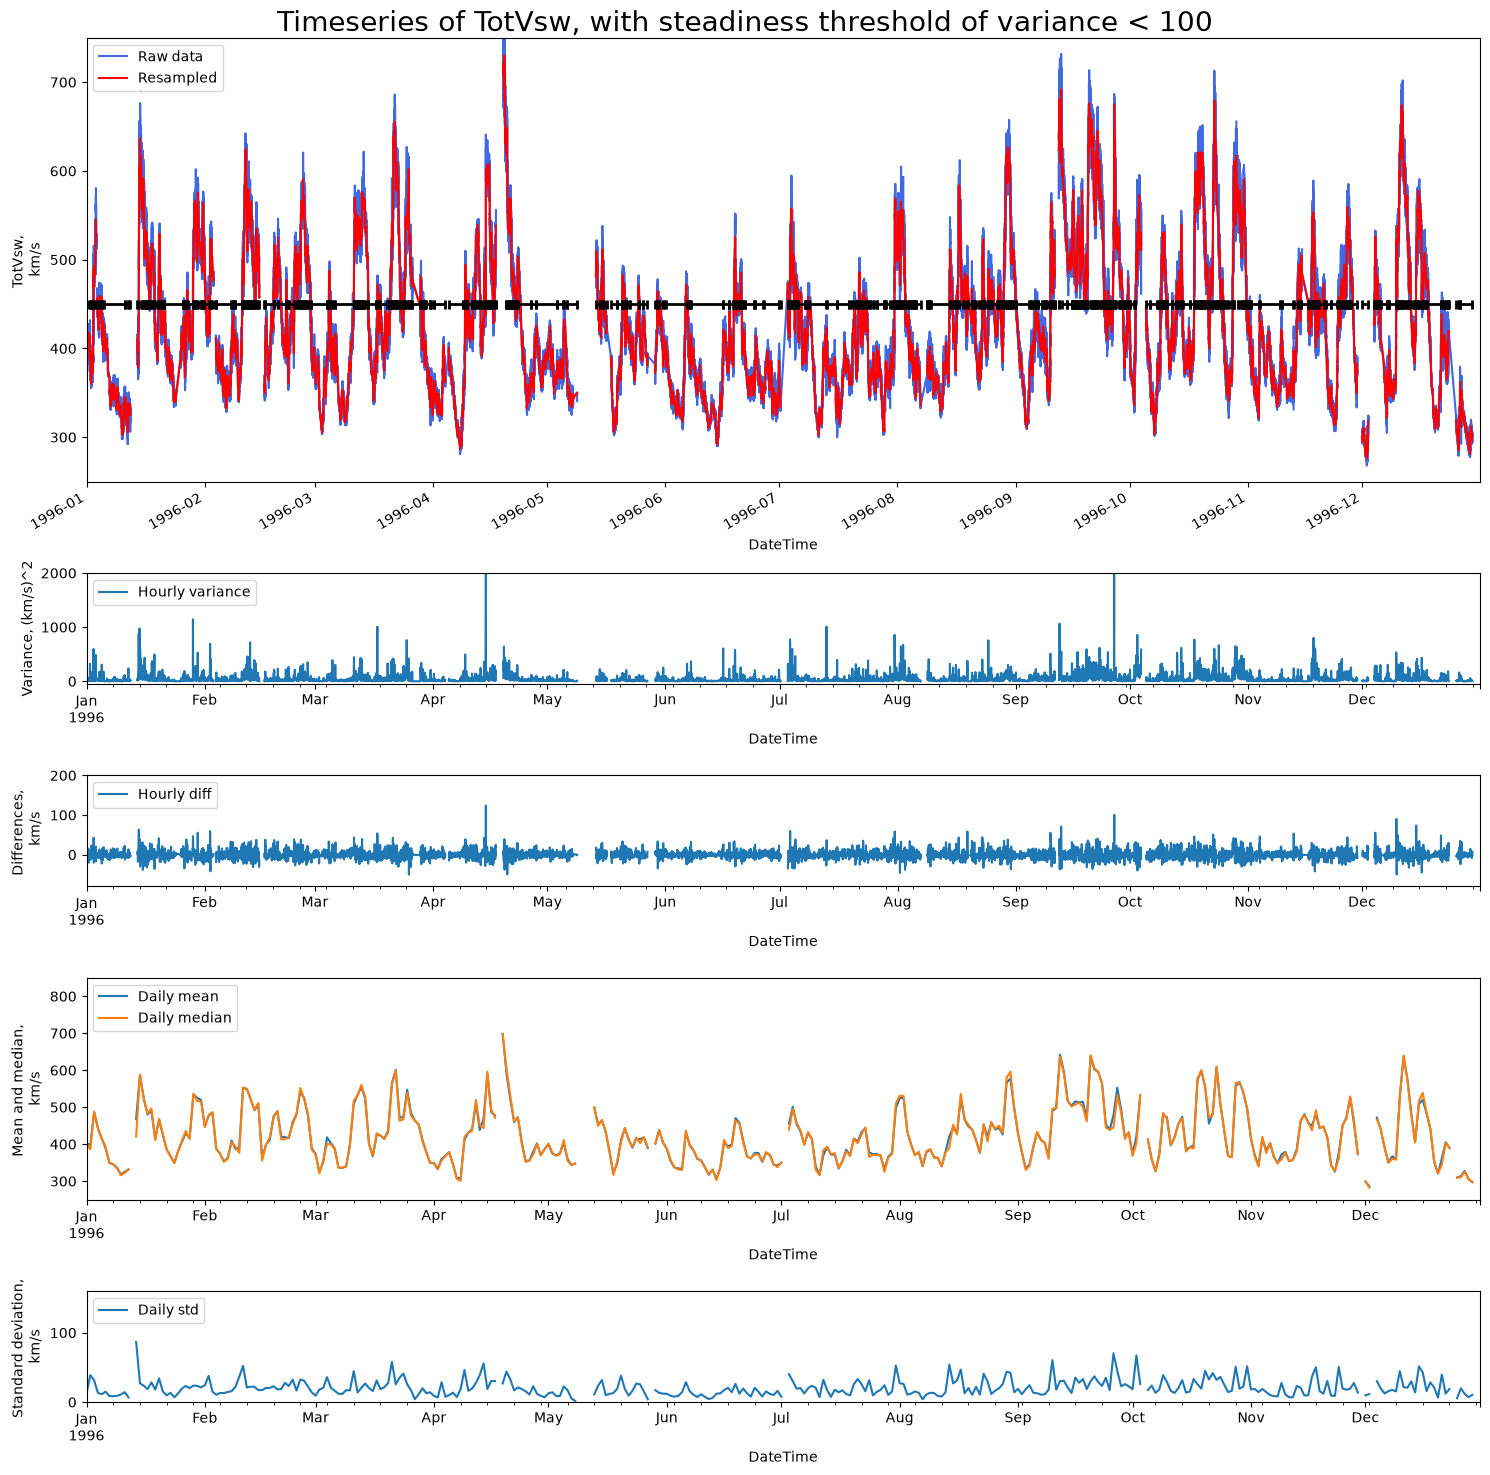

[20.0, 7.0, 9.0, 8.0, 12.0, 13.0, 9.0, 132.0, 21.0, 12.0, 6.0, 3.0, 1.0, 1.0, 1.0, 1.0, 7.0, 10.0, 4.0, 10.0, 22.0, 3.0, 6.0, 5.0, 1.0, 7.0, 116.0, 3.0, 1.0, 16.0, 31.0, 4.0, 5.0, 7.0, 20.0, 2.0, 3.0, 3.0, 35.0, 1.0, 1.0, 16.0, 2.0, 93.0, 11.0, 10.0, 39.0, 1.0, 1.0, 3.0, 2.0, 1.0, 1.0, 4.0, 1.0, 2.0, 3.0, 1.0, 7.0, 7.0, 1.0, 6.0, 8.0, 5.0, 51.0, 1.0, 20.0, 48.0, 6.0, 4.0, 32.0, 2.0, 17.0, 1.0, 1.0, 1.0, 1.0, 1.0, 4.0, 9.0, 2.0, 5.0, 16.0, 103.0, 6.0, 8.0, 9.0, 16.0, 115.0, 2.0, 5.0, 4.0, 6.0, 3.0, 1.0, 3.0, 1.0, 1.0, 6.0, 11.0, 10.0, 47.0, 6.0, 11.0, 50.0, 11.0, 6.0, 1.0, 2.0, 2.0, 8.0, 2.0, 4.0, 16.0, 16.0, 6.0, 1.0, 4.0, 10.0, 6.0, 50.0, 1.0, 8.0, 2.0, 7.0, 2.0, 26.0, 2.0, 19.0, 70.0, 91.0, 7.0, 5.0, 1.0, 31.0, 18.0, 3.0, 13.0, 10.0, 20.0, 5.0, 1.0, 1.0, 3.0, 6.0, 3.0, 3.0, 9.0, 7.0, 1.0, 1.0, 5.0, 4.0, 6.0, 1.0, 1.0, 3.0, 2.0, 8.0, 1.0, 8.0, 86.0, 29.0, 128.0, 38.0, 19.0, 61.0, 23.0, 8.0, 3.0, 6.0, 21.0, 37.0, 30.0, 4.0, 13.0, 2.0, 18.0, 60.0, 22.0, 27.0, 14.0, 3.0, 28.0, 12.0, 133.

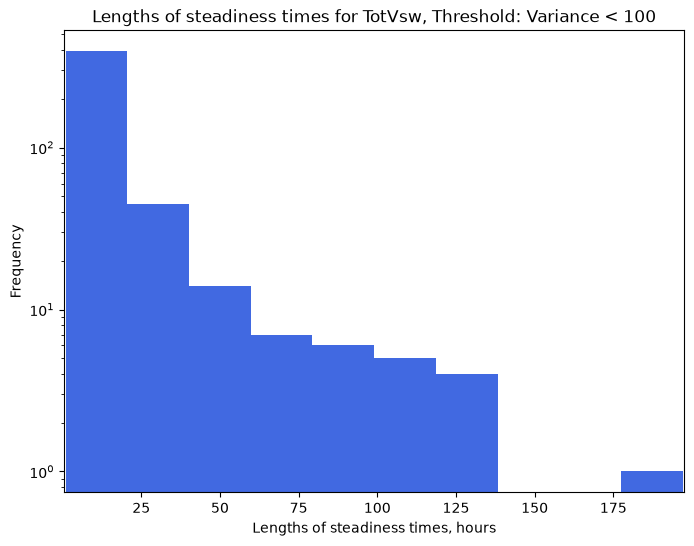

In [23]:
# TotVsw
Variable = "TotVsw"
Unit = "km/s"
# YLim = [[250, 750],[-50, 1500],[-50, 100], [250, 750], [0, 40]]
YLim = [[250, 750],[-50, 2000],[-80, 200], [250, 850], [0, 160]]
XLim = [dataTSConcat[1].to_dataframe().index[0], dataTSConcat[1].to_dataframe().index[-1]]
Thres = 10**2
resamplerate = "1h"

# import sunpy
# print(sunpy.__version__)

# # BMag
# Variable = "BMag"
# Unit = "nT"
# YLim = [[-1, 20],[-2, 10],[-5, 6], [0, 15], [0, 3]]
# Thres = 0.1

#Timeseries
resamplerate = "1h"

#Histograms
Bins = [1,2,3,4,5,6,7,8,9,10,11,12]
Histogram = (8,6)


fig, axs = plt.subplots(5,1, height_ratios=[4,1,1,2, 1], figsize=(15, 15)) # , sharex=True
# rawData = dataTSConcat[1].to_dataframe()

## interpolated raw data, no restrictions
# rawData = dataTSConcat[1].to_dataframe().interpolate() # interpolated raw data

## interpolate only over certain timespans/ jumps
#####
def interpolate_small_jumps(series, max_jump):

    before = series.ffill()
    after = series.bfill()

    fill_allowed = series.isna() & ((after - before).abs() < max_jump)

    interpolated = series.interpolate(method="time")
    return series.where(~fill_allowed, interpolated)

rawData = dataTSConcat[1].to_dataframe() # raw data
rawData = rawData.sort_index().apply(interpolate_small_jumps, max_jump=50) #np.sqrt(Thres))
#####


# Resample data - Choose a resample rate that seems accurate to changes in data
# resampledRate1 = resampleMean(rawData, "1h").to_dataframe()
resampledRate1 = rawData.resample(resamplerate).mean()

# Plot
# print(axs[0])
rawData[Variable].plot(color=colour1, label = "Raw data", ax=axs[0])
resampledRate1[Variable].plot(color=colour2, label = "Resampled", ax=axs[0])

# Variance
hourly_var = rawData[Variable].resample(resamplerate).var()
hourly_var.plot(ax=axs[1], label="Hourly variance")

## Daragh's testing code
# # plt.show()
# # 1/0
# # Plot
# axs[0].plot(rawData.index, rawData[Variable])
# axs[0].plot(resampledRate1.index, resampledRate1[Variable])
# # # Variance
# hourly_var = rawData.resample(resamplerate).var()
# axs[1].plot(hourly_var.index, hourly_var[Variable])
# # plt.show()
# # 1/0



# Differences
hourly_diff = resampledRate1[Variable].diff()
hourly_diff.plot(ax=axs[2], label="Hourly diff")


# Mean/median/standard dev
# ##Hourly
# hourly_mean = rawData[Variable].resample(resamplerate).mean()
# hourly_median = rawData[Variable].resample(resamplerate).median()
# hourly_mean.plot(ax=axs[3], label="Hourly mean")
# hourly_median.plot(ax=axs[3], label="Hourly median")

# hourly_std = rawData[Variable].resample(resamplerate).std()
# hourly_std.plot(ax=axs[4], label="Hourly std")

## Daily
statsResampleRate = "1d"
daily_mean = rawData[Variable].resample(statsResampleRate).mean()
daily_median = rawData[Variable].resample(statsResampleRate).median()
daily_mean.plot(ax=axs[3], label="Daily mean")
daily_median.plot(ax=axs[3], label="Daily median")

daily_std = rawData[Variable].resample(statsResampleRate).std()
daily_std.plot(ax=axs[4], label="Daily std")

# Steadiness defn.
mask_var = hourly_var.between(0, Thres) # check if values of variance are between 0 and your threshold value (if they are = True, if they aren't = False)

values = hourly_var.reindex(mask_var.index) # set the hourly_var index to the same as the mask_var index (I think these are the same anyway?)
valid = mask_var.fillna(False).astype(bool) & values.notna() # valid condition is that the value is OUTSIDE the threshold set, and the value is not a nan

# print(hourly_var)
# print(mask_var)
# print(values)
# print(valid)

is_start = valid & ~valid.shift(1, fill_value=False) # the point is a starting point if the value is outside the threshold and the next one is not
is_end = valid & ~valid.shift(-1, fill_value=False) # the point is an ending point if the value is outside the threshold and the previous one was not

StartsPossible = valid.index[is_start].tolist()
EndsPossible = valid.index[is_end].tolist()

# print(len(StartsPossible))
# print(len(EndsPossible))
# print(StartsPossible)
# print(EndsPossible)

Starts = []
Ends = []
for i in range(len(StartsPossible)):
    # if StartsPossible[i] == EndsPossible[i]:
        # print("Same")
    if StartsPossible[i] != EndsPossible[i]: # Remove any points where the start and end are the same (is this even possible with the above logic?)
        Starts.append(StartsPossible[i])
        Ends.append(EndsPossible[i])

# print(len(Starts))
# print(len(Ends))
# print(Starts)
# print(Ends)

# Starts = StartsPossible.copy()
# Ends = EndsPossible.copy()

YLabel = [ Variable+ ", \n" + Unit, "Variance, (" + Unit + ")^2", "Differences, \n " + Unit, "Mean and median, \n" + Unit, "Standard deviation, \n" + Unit]
for i in range(0,5):
    axs[i].legend(loc="upper left")
    axs[i].set_ylim(YLim[i])
    axs[i].set_ylabel(YLabel[i])
    axs[i].set_xlim(XLim)
    # for j in range(len(Starts)):
    #     axs[i].axvspan(Starts[j], Ends[j], color="goldenrod", alpha = 0.7)

# plt.xlim(XLim)

for j in range(len(Starts)):
    axs[0].hlines(450, Starts[j], Ends[j], linewidth=2, color="black", alpha = 1)
    axs[0].vlines( Starts[j], 445, 455, linewidth=2, color="black", alpha = 1)
    axs[0].vlines(Ends[j], 445, 455, linewidth=2, color="black", alpha = 1)

print("Caption: Time series of " + Variable + " for the year 1996 with the calculated hourly variance, difference between neighbouring points, \nhourly mean, median and standard deviation. Black horizontal lines show the regions of steadiness for this threshold.")
plt.suptitle("Timeseries of " + Variable + ", with steadiness threshold of variance < " + str(Thres), fontsize = 20)
plt.tight_layout()
plt.show()

# # Seconds
# TausMin = []
# for i in range(len(Starts)):
#     TausMin.append((Ends[i] - Starts[i]).total_seconds())
# plt.xlabel("Lengths of steadiness times, s")

# # Minutes
# TausMin = []
# for i in range(len(Starts)):
#     TausMin.append((Ends[i] - Starts[i]).total_seconds()/60)
# plt.xlabel("Lengths of steadiness times, mins")

# Hours - only this one has use because the resample rate is in hours
TausMin = []
for i in range(len(Starts)):
    TausMin.append((Ends[i] - Starts[i]).total_seconds()/3600)

print(TausMin)

fig = plt.figure(figsize=Histogram)
plt.hist(TausMin, bins=10, color=colour1, label = "Year of data at minimum (1996)")
plt.title("Lengths of steadiness times for " + Variable + ", Threshold: Variance < " + str(Thres))
plt.ylabel("Frequency")
plt.xlabel("Lengths of steadiness times, hours")
plt.yscale('log')
plt.xlim(min(TausMin)-0.5, max(TausMin)+0.5)
plt.show()

In [24]:
rawData[Variable].plot(color=colour1, label = "Raw data", ax=axs[0])
resampledRate1[Variable].plot(color=colour2, label = "Resampled", ax=axs[0])

# Variance
hourly_var = rawData[Variable].resample(resamplerate).var()
hourly_var.plot(ax=axs[1], label="Hourly variance")

<Axes: xlabel='DateTime', ylabel='Variance, (km/s)^2'>

In [25]:
rawData.index.values[-1]

np.datetime64('1996-12-31T23:59:00.000000')

In [26]:

hourly_var.index.values[-1]

np.datetime64('1996-12-31T23:00:00.000000')

In [27]:
resampledRate1[Variable]

DateTime
1996-01-01 00:00:00    423.054517
1996-01-01 01:00:00    395.536980
1996-01-01 02:00:00    389.452905
1996-01-01 03:00:00    387.769294
1996-01-01 04:00:00    385.547531
                          ...    
1996-12-31 19:00:00           NaN
1996-12-31 20:00:00           NaN
1996-12-31 21:00:00           NaN
1996-12-31 22:00:00           NaN
1996-12-31 23:00:00           NaN
Freq: h, Name: TotVsw, Length: 8784, dtype: float64

In [28]:
rawData[Variable]

DateTime
1996-01-01 00:00:00           NaN
1996-01-01 00:01:00           NaN
1996-01-01 00:02:00           NaN
1996-01-01 00:03:00    434.562159
1996-01-01 00:04:00    434.562159
                          ...    
1996-12-31 23:55:00           NaN
1996-12-31 23:56:00           NaN
1996-12-31 23:57:00           NaN
1996-12-31 23:58:00           NaN
1996-12-31 23:59:00           NaN
Name: TotVsw, Length: 509857, dtype: float64

# Maximum

Caption: Time series of TotVsw for the year 2001 with the calculated hourly variance, difference between neighbouring points, 
hourly mean, median and standard deviation. Black horizontal lines show the regions of steadiness for this threshold.


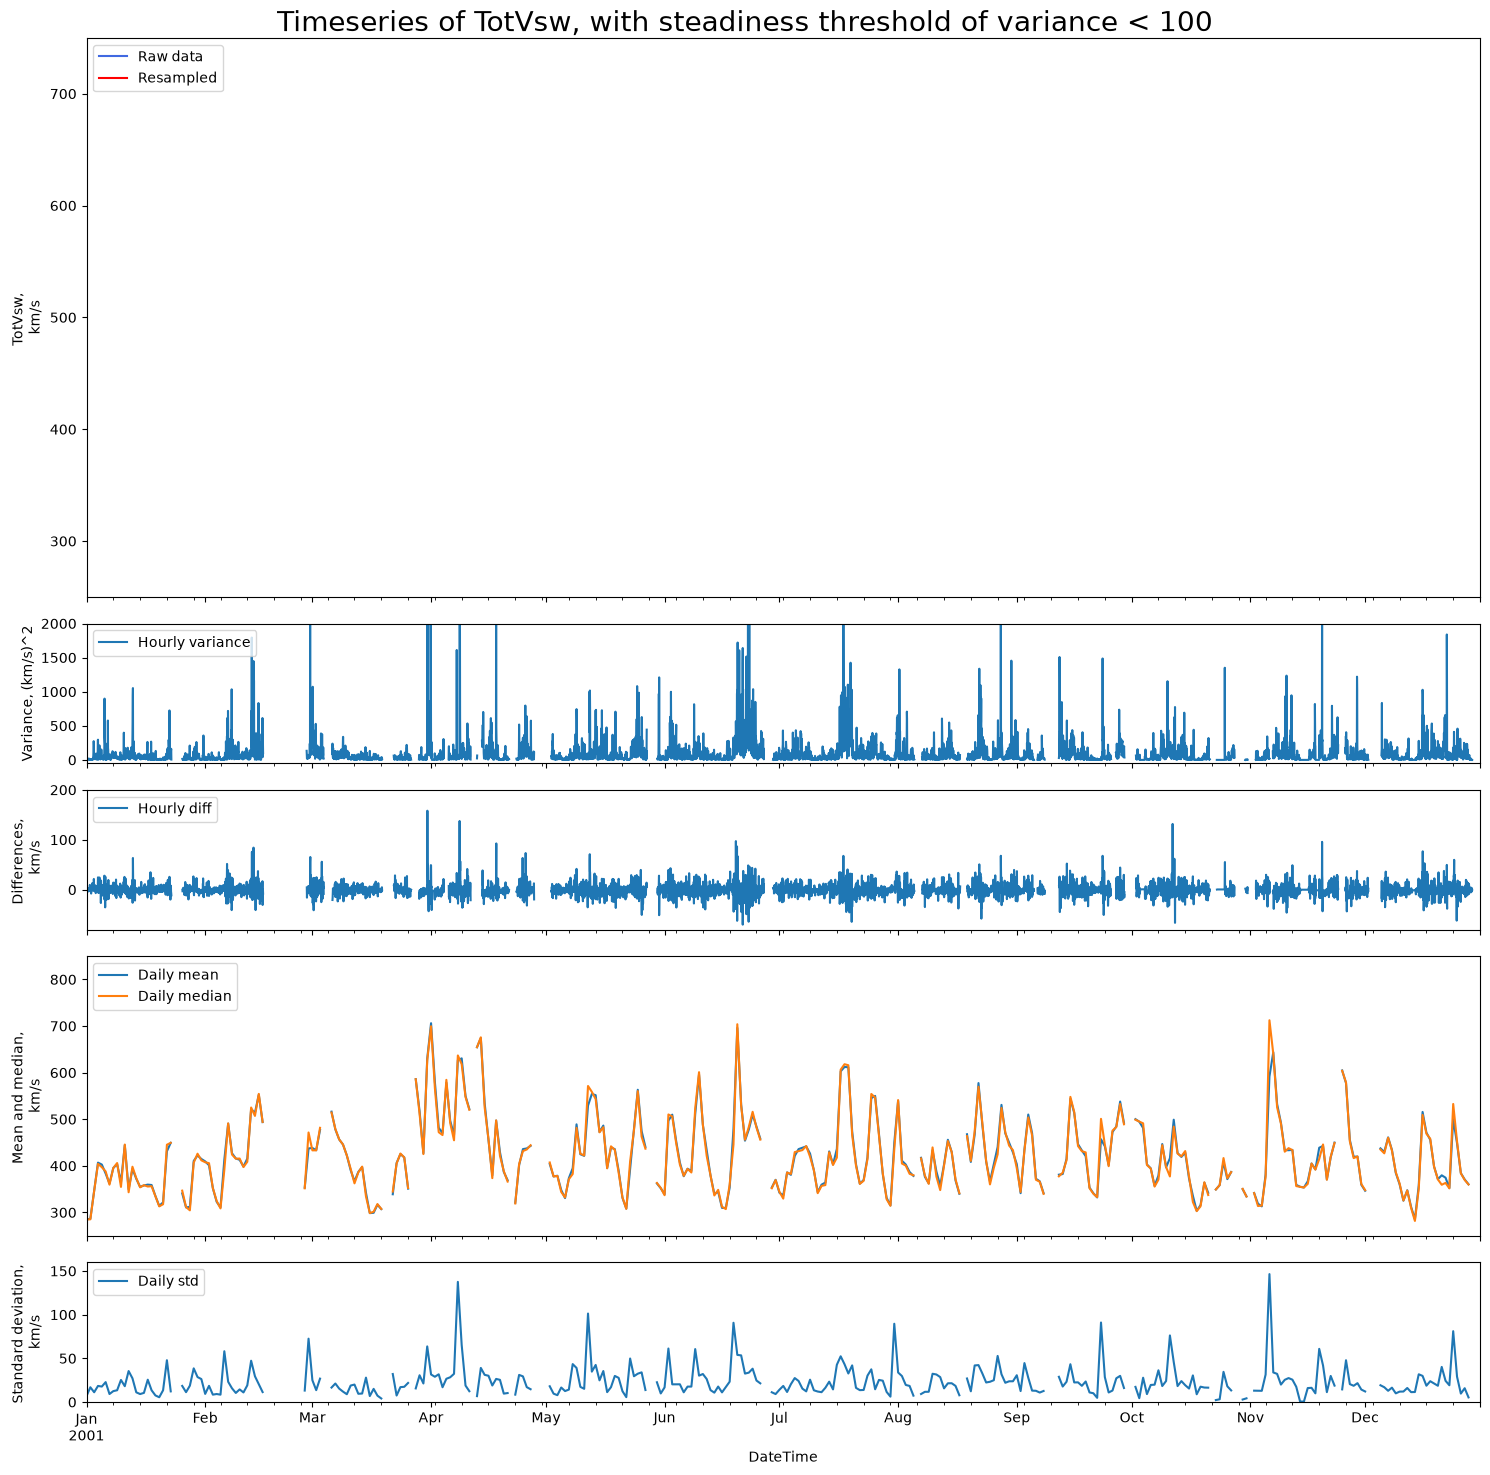

[43.0, 23.0, 6.0, 10.0, 17.0, 10.0, 2.0, 25.0, 2.0, 11.0, 28.0, 19.0, 1.0, 5.0, 12.0, 6.0, 5.0, 3.0, 4.0, 1.0, 4.0, 76.0, 21.0, 27.0, 71.0, 1.0, 1.0, 4.0, 18.0, 25.0, 21.0, 3.0, 2.0, 8.0, 29.0, 2.0, 48.0, 43.0, 38.0, 2.0, 2.0, 2.0, 4.0, 2.0, 13.0, 5.0, 2.0, 24.0, 15.0, 5.0, 16.0, 4.0, 2.0, 4.0, 1.0, 4.0, 1.0, 1.0, 3.0, 6.0, 1.0, 18.0, 1.0, 1.0, 1.0, 4.0, 9.0, 1.0, 2.0, 2.0, 1.0, 5.0, 11.0, 8.0, 8.0, 6.0, 5.0, 4.0, 4.0, 5.0, 74.0, 25.0, 3.0, 2.0, 16.0, 76.0, 42.0, 23.0, 9.0, 25.0, 13.0, 35.0, 1.0, 1.0, 2.0, 53.0, 12.0, 1.0, 1.0, 1.0, 1.0, 22.0, 7.0, 7.0, 15.0, 2.0, 6.0, 2.0, 3.0, 12.0, 3.0, 1.0, 1.0, 3.0, 7.0, 10.0, 1.0, 1.0, 1.0, 1.0, 12.0, 6.0, 41.0, 1.0, 22.0, 15.0, 13.0, 2.0, 1.0, 2.0, 8.0, 1.0, 14.0, 1.0, 3.0, 1.0, 2.0, 32.0, 2.0, 62.0, 6.0, 11.0, 1.0, 1.0, 1.0, 18.0, 1.0, 2.0, 22.0, 4.0, 6.0, 9.0, 2.0, 2.0, 7.0, 2.0, 1.0, 1.0, 2.0, 5.0, 6.0, 23.0, 9.0, 3.0, 10.0, 4.0, 18.0, 5.0, 28.0, 1.0, 26.0, 1.0, 1.0, 3.0, 5.0, 2.0, 1.0, 1.0, 6.0, 5.0, 4.0, 7.0, 40.0, 10.0, 1.0, 8.0, 2.0, 6.0,

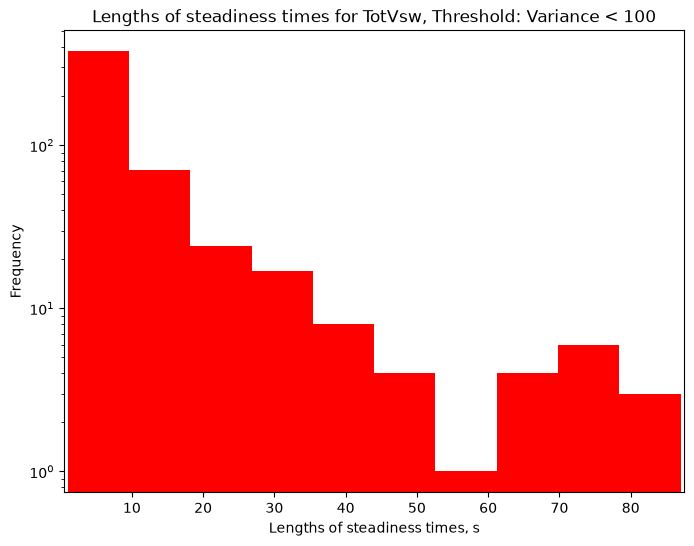

In [29]:
# TotVsw
Variable = "TotVsw"
Unit = "km/s"
# YLim = [[250, 750],[-50, 1100],[-50, 70], [250, 650], [0, 40]]
YLim = [[250, 750],[-50, 2000],[-80, 200], [250, 850], [0, 160]]
# Thres = 5
resamplerate = "1h"

# # BMag
# Variable = "BMag"
# Unit = "nT"
# YLim = [[-1, 20],[-2, 10],[-5, 6], [0, 15], [0, 3]]
# Thres = 0.1


fig, axs = plt.subplots(5,1, sharex=True, height_ratios=[4,1,1,2, 1], figsize=(15, 15))
# rawData = dataTSConcat[2].to_dataframe()

## interpolated raw data, no restrictions
# rawData = dataTSConcat[2].to_dataframe().interpolate() # interpolated raw data

## interpolate only over certain timespans/ jumps
####
def interpolate_small_jumps(series, max_jump):

    before = series.ffill()
    after = series.bfill()

    fill_allowed = series.isna() & ((after - before).abs() < max_jump)

    interpolated = series.interpolate(method="time")
    return series.where(~fill_allowed, interpolated)

rawData = dataTSConcat[2].to_dataframe() # raw data
rawData = rawData.sort_index().apply(interpolate_small_jumps, max_jump=50) #np.sqrt(Thres))
####

# Resample data - Choose a resample rate that seems accurate to changes in data
# resampledRate1 = resampleMean(rawData, "1h").to_dataframe()
resampledRate1 = rawData.resample(resamplerate).mean()

# Plot
# print(axs[0])
rawData[Variable].plot(color=colour1, label = "Raw data", ax=axs[0])
resampledRate1[Variable].plot(color=colour2, label = "Resampled", ax=axs[0])

# Variance
hourly_var = rawData[Variable].resample(resamplerate).var()
hourly_var.plot(ax=axs[1], label="Hourly variance")

# Differences
hourly_diff = resampledRate1[Variable].diff()
hourly_diff.plot(ax=axs[2], label="Hourly diff")

# Mean/median/standard dev
# ##Hourly
# hourly_mean = rawData[Variable].resample(resamplerate).mean()
# hourly_median = rawData[Variable].resample(resamplerate).median()
# hourly_mean.plot(ax=axs[3], label="Hourly mean")
# hourly_median.plot(ax=axs[3], label="Hourly median")

# hourly_std = rawData[Variable].resample(resamplerate).std()
# hourly_std.plot(ax=axs[4], label="Hourly std")

## Daily
statsResampleRate = "1d"
daily_mean = rawData[Variable].resample(statsResampleRate).mean()
daily_median = rawData[Variable].resample(statsResampleRate).median()
daily_mean.plot(ax=axs[3], label="Daily mean")
daily_median.plot(ax=axs[3], label="Daily median")

daily_std = rawData[Variable].resample(statsResampleRate).std()
daily_std.plot(ax=axs[4], label="Daily std")

# Steadiness defn.
mask_var = hourly_var.between(0, Thres)

values = hourly_var.reindex(mask_var.index)
valid = mask_var.fillna(False).astype(bool) & values.notna()

# print(hourly_var)
# print(mask_var)
# print(values)
# print(valid)

is_start = valid & ~valid.shift(1, fill_value=False)
is_end = valid & ~valid.shift(-1, fill_value=False)

StartsPossible = valid.index[is_start].tolist()
EndsPossible = valid.index[is_end].tolist()

# print(len(StartsPossible))
# print(len(EndsPossible))
# print(StartsPossible)
# print(EndsPossible)

Starts = []
Ends = []
for i in range(len(StartsPossible)):
    # if StartsPossible[i] == EndsPossible[i]:
        # print("Same")
    if StartsPossible[i] != EndsPossible[i]:
        Starts.append(StartsPossible[i])
        Ends.append(EndsPossible[i])

# print(len(Starts))
# print(len(Ends))
# print(Starts)
# print(Ends)

# Starts = StartsPossible.copy()
# Ends = EndsPossible.copy()

YLabel = [ Variable+ ", \n" + Unit, "Variance, (" + Unit + ")^2", "Differences, \n " + Unit, "Mean and median, \n" + Unit, "Standard deviation, \n" + Unit]
for i in range(0,5):
    axs[i].legend(loc="upper left")
    axs[i].set_ylim(YLim[i])
    axs[i].set_ylabel(YLabel[i])
    # for j in range(len(Starts)):
    #     axs[i].axvspan(Starts[j], Ends[j], color="goldenrod", alpha = 0.7)

for j in range(len(Starts)):
    axs[0].hlines(450, Starts[j], Ends[j], linewidth=2, color="black", alpha = 1)
    axs[0].vlines( Starts[j], 445, 455, linewidth=2, color="black", alpha = 1)
    axs[0].vlines(Ends[j], 445, 455, linewidth=2, color="black", alpha = 1)


print("Caption: Time series of " + Variable + " for the year 2001 with the calculated hourly variance, difference between neighbouring points, \nhourly mean, median and standard deviation. Black horizontal lines show the regions of steadiness for this threshold.")
plt.suptitle("Timeseries of " + Variable + ", with steadiness threshold of variance < " + str(Thres), fontsize = 20)
plt.tight_layout()
plt.show()

# # Seconds
# TausMax = []
# for i in range(len(Starts)):
#     TausMax.append((Ends[i] - Starts[i]).total_seconds())
# plt.xlabel("Lengths of steadiness times, s")

# # Minutes
# TausMax = []
# for i in range(len(Starts)):
#     TausMax.append((Ends[i] - Starts[i]).total_seconds()/60)
# plt.xlabel("Lengths of steadiness times, mins")

# Hours - only this one has use because the resample rate is in hours
TausMax = []
for i in range(len(Starts)):
    TausMax.append((Ends[i] - Starts[i]).total_seconds()/3600)

print(TausMax)

fig = plt.figure(figsize=Histogram)
plt.hist(TausMax, bins=10, color=colour2, label = "Year of data at maximum (2001)")
plt.yscale('log')
plt.title("Lengths of steadiness times for " + Variable + ", Threshold: Variance < " + str(Thres))
plt.ylabel("Frequency")
plt.xlabel("Lengths of steadiness times, s")
plt.xlim(min(TausMax)-0.5, max(TausMax)+0.5)
plt.show()

Caption: Lengths of steadiness times for (threshold: Variance < 100) for a year at minimum (blue) and maximum (red). 
The steadiness times are fairly similar for both, particularly for durations of less than 20 hours. For the higher 
durations the minimum year seems to have more steadiness times than the maximum year for most bins (each bin spans 
4 hours). This would imply longer regions of steadiness during minimum. This could be affected by more common CMEs 
during the maximum year which, although their values have been omitted, still could cause a shortening of ambient 
wind steady times by creating data gaps.
13.753164556962025 9.214007782101167
23.134997337365856 13.861211671280703


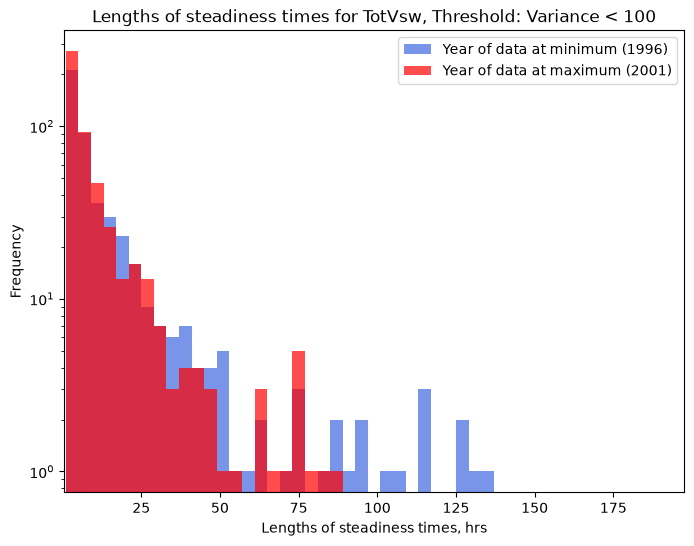

In [56]:
fig = plt.figure(figsize=Histogram)
Bins = np.arange(1,140,4)
# print(Bins)
plt.hist(TausMin, bins=Bins, color=colour1, label = "Year of data at minimum (1996)", alpha = 0.7)#, density=True)
plt.hist(TausMax, bins=Bins, color=colour2, label = "Year of data at maximum (2001)", alpha = 0.7)#, density=True)
plt.yscale('log')
plt.title("Lengths of steadiness times for " + Variable + ", Threshold: Variance < " + str(Thres))
plt.ylabel("Frequency")
plt.xlabel("Lengths of steadiness times, hrs")

MinTau = min(TausMin + TausMax)
MaxTau = max(TausMin + TausMax)
plt.xlim(MinTau-0.5, MaxTau+0.5)
plt.legend()

print("Caption: Lengths of steadiness times for (threshold: Variance < " + str(Thres) + ") for a year at minimum (blue) and maximum (red). \nThe steadiness times are fairly similar for both, particularly for durations of less than 20 hours. For the higher \ndurations the minimum year seems to have more steadiness times than the maximum year for most bins (each bin spans \n" +str(Bins[1]-Bins[0])+" hours). This would imply longer regions of steadiness during minimum. This could be affected by more common CMEs \nduring the maximum year which, although their values have been omitted, still could cause a shortening of ambient \nwind steady times by creating data gaps.")

distrib_mean_min = np.mean(TausMin)
distrib_mean_max = np.mean(TausMax)
print(distrib_mean_min, distrib_mean_max)

distrib_std_min = np.std(TausMin)
distrib_std_max = np.std(TausMax)
print(distrib_std_min, distrib_std_max)

In [31]:
# Minimum
    #STEADY
TotSteadyTimeMin = sum(TausMin) # Sum the number of hours of all the steadiness regions
    #TOTAL TIME IN SPAN
rawDataMin = dataTSConcat[1].to_dataframe() # get the raw data again
resampledRate1Min = rawDataMin.resample("1h").mean() # get the resampled data again
TotalTimeMin = len(resampledRate1Min)
# print("Total possible time in timespan: " + str(TotalTime) + "hours")
    #TOTAL DATA AVAILABLE
TotTimeDataAvailableMin = resampledRate1Min[Variable].notna().sum() # take the non-nan values (this will include steady and unsteady regions)
    #TOTAL DATA GAPS + CMES
TotTimeDataUnavailableMin = resampledRate1Min[Variable].isna().sum()
    # DATA GAPS
TotDataGapsMin = resampledRate1Min[Variable].isna().sum() - TotalTimeRemovedByCMEsMin
    # UNSTEADY
TotUnsteadyTimeMin = TotTimeDataAvailableMin - TotSteadyTimeMin
    # PERCENTAGE STEADY OF AVAILABLE DATA - BIASED FOR LACK OF CMES
SteadinessPercentageMinAvailableData = TotSteadyTimeMin/TotTimeDataAvailableMin * 100
SteadinessPercentageMinTotalTime = TotSteadyTimeMin/TotalTimeMin * 100

print("Minimum year 1996")
# print("Total time spanned (end date - start date): " + str(TotalTime) + " hours")
print("Total time spanned (data available + data not available): " + str(TotalTimeMin) + " hours")
print("Total time steady : " + str(TotSteadyTimeMin) +" hours")
print("Total time unsteady (available data - steady): " + str(TotUnsteadyTimeMin) +" hours")
print("Total time data available for : " + str(TotTimeDataAvailableMin) +" hours")
print("Percentage of total data available that " + Variable + " is steady for : " + str(round(SteadinessPercentageMinAvailableData)) +" %")
print("Percentage of total time in timespan that " + Variable + " is steady for : " + str(round(SteadinessPercentageMinTotalTime)) +" %")
print("Total time that is taken up by nan values (data gaps + CMEs removed): " + str(TotTimeDataUnavailableMin))
print("Total time taken up by data gaps: " + str(TotDataGapsMin))
print("Time removed by CMEs: "+ str(TotalTimeRemovedByCMEsMin) + " hours.")
print("Percentage of total time that is removed during CME removal : " + str(round(TotalTimeRemovedByCMEsMin/(TotalTimeMin) * 100)) +" %")
print("Percentage of total time - steadiness + CMEs: " + str( round( TotalTimeRemovedByCMEsMin/(TotalTimeMin) * 100 + SteadinessPercentageMinTotalTime)) + "%")

############
# Maximum
    #STEADY
TotSteadyTimeMax = sum(TausMax) # Sum the number of hours of all the steadiness regions
    #TOTAL TIME IN SPAN
rawDataMax = dataTSConcat[2].to_dataframe() # get the raw data again
resampledRate1Max = rawDataMax.resample("1h").mean() # get the resampled data again
TotalTimeMax = len(resampledRate1Max)
# print("Total possible time in timespan: " + str(TotalTime) + "hours")
    #TOTAL DATA AVAILABLE
TotTimeDataAvailableMax = resampledRate1Max[Variable].notna().sum() # take the non-nan values (this will include steady and unsteady regions)
    #TOTAL DATA GAPS + CMES
TotTimeDataUnavailableMax = resampledRate1Max[Variable].isna().sum()
    # DATA GAPS
TotDataGapsMax = resampledRate1Max[Variable].isna().sum() - TotalTimeRemovedByCMEsMax
    # UNSTEADY
TotUnsteadyTimeMax = TotTimeDataAvailableMax - TotSteadyTimeMax
    # PERCENTAGE STEADY OF AVAILABLE DATA - BIASED FOR LACK OF CMES
SteadinessPercentageMaxAvailableData = TotSteadyTimeMax/TotTimeDataAvailableMax * 100
SteadinessPercentageMaxTotalTime = TotSteadyTimeMax/TotalTimeMax * 100

print("-----------------")
print("Maximum year 2001")
# print("Total time spanned (end date - start date): " + str(TotalTime) + " hours")
print("Total time spanned (data available + data not available): " + str(TotalTimeMax) + " hours")
print("Total time steady : " + str(TotSteadyTimeMax) +" hours")
print("Total time unsteady (available data - steady): " + str(TotUnsteadyTimeMax) +" hours")
print("Total time data available for : " + str(TotTimeDataAvailableMax) +" hours")
print("Percentage of total data available that " + Variable + " is steady for : " + str(round(SteadinessPercentageMaxAvailableData)) +" %")
print("Percentage of total time in timespan that " + Variable + " is steady for : " + str(round(SteadinessPercentageMaxTotalTime)) +" %")
print("Total time that is taken up by nan values (data gaps + CMEs removed): " + str(TotTimeDataUnavailableMax))
print("Total time taken up by data gaps: " + str(TotDataGapsMax))
print("Time removed by CMEs: "+ str(TotalTimeRemovedByCMEsMax) + " hours.")
print("Percentage of total time that is removed during CME removal : " + str(round(TotalTimeRemovedByCMEsMax/(TotalTimeMax) * 100)) +" %")
print("Percentage of total time - steadiness + CMEs: " + str( round( TotalTimeRemovedByCMEsMax/(TotalTimeMax) * 100 + SteadinessPercentageMaxTotalTime)) + "%")

Minimum year 1996
Total time spanned (data available + data not available): 8784 hours
Total time steady : 6519.0 hours
Total time unsteady (available data - steady): 1211.0 hours
Total time data available for : 7730 hours
Percentage of total data available that TotVsw is steady for : 84 %
Percentage of total time in timespan that TotVsw is steady for : 74 %
Total time that is taken up by nan values (data gaps + CMEs removed): 1054
Total time taken up by data gaps: 790.6833333333334
Time removed by CMEs: 263.31666666666666 hours.
Percentage of total time that is removed during CME removal : 3 %
Percentage of total time - steadiness + CMEs: 77%
-----------------
Maximum year 2001
Total time spanned (data available + data not available): 8760 hours
Total time steady : 4736.0 hours
Total time unsteady (available data - steady): 2152.0 hours
Total time data available for : 6888 hours
Percentage of total data available that TotVsw is steady for : 69 %
Percentage of total time in timespan th

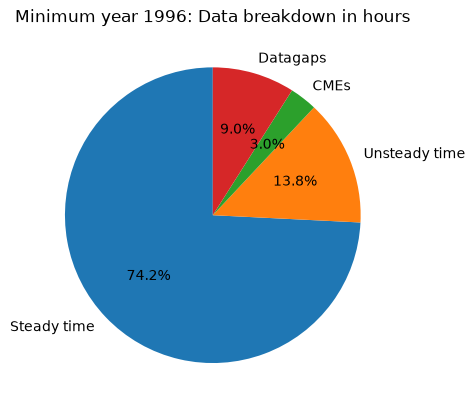

total hours = 8784.0


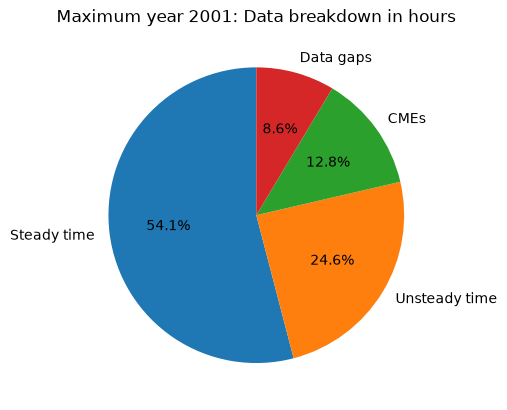

total hours = 8760.0


In [35]:
## Minimum year 1996
# Total time spanned (data available + data not available): 8784 hours
# Total time steady : 5948.0 hours
# Total time unsteady (available data - steady): 1700.0 hours
# Total time data available for : 7648 hours
# Percentage of total data available that TotVsw is steady for : 78 %
# Percentage of total time in timespan that TotVsw is steady for : 68 %
# Total time that is taken up by nan values (data gaps + CMEs removed): 1136
# Total time taken up by data gaps: 776.6833333333334
# Time removed by CMEs: 359.31666666666666 hours.
# Percentage of total time that is removed during CME removal : 4 %
# Percentage of total time - steadiness + CMEs: 72%

LabelsMin = ["Steady time", "Unsteady time", "CMEs", "Datagaps"]
min1996 = np.array([TotSteadyTimeMin, TotUnsteadyTimeMin, TotalTimeRemovedByCMEsMin, TotDataGapsMin])

plt.pie(min1996, labels=LabelsMin, startangle = 90, autopct='%1.1f%%')
plt.title("Minimum year 1996: Data breakdown in hours")
plt.show() 
print("total hours = " + str(TotSteadyTimeMin+TotUnsteadyTimeMin+TotalTimeRemovedByCMEsMin+TotDataGapsMin))


## Maximum year 2001
# Total time spanned (data available + data not available): 8760 hours
# Total time steady : 4098.0 hours
# Total time unsteady (available data - steady): 2574.0 hours
# Total time data available for : 6672 hours
# Percentage of total data available that TotVsw is steady for : 61 %
# Percentage of total time in timespan that TotVsw is steady for : 47 %
# Total time that is taken up by nan values (data gaps + CMEs removed): 2088
# Total time taken up by data gaps: 692.9000000000001
# Time removed by CMEs: 1395.1 hours.
# Percentage of total time that is removed during CME removal : 16 %
# Percentage of total time - steadiness + CMEs: 63%

LabelsMax = ["Steady time", "Unsteady time", "CMEs", "Data gaps"]
max2001 = np.array([TotSteadyTimeMax, TotUnsteadyTimeMax, TotalTimeRemovedByCMEsMax, TotDataGapsMax])

plt.pie(max2001, labels=LabelsMax, startangle = 90, autopct='%1.1f%%')
plt.title("Maximum year 2001: Data breakdown in hours")
plt.show() 
print("total hours = " + str(TotSteadyTimeMax+TotUnsteadyTimeMax+TotalTimeRemovedByCMEsMax+TotDataGapsMax))

In [33]:
print(len(dataTSConcat[0].to_dataframe()))
print(len(dataTSConcat[1].to_dataframe()))
print(len(dataTSConcat[2].to_dataframe()))

44640
509857
460539


AttributeError: 'GenericTimeSeries' object has no attribute 'resample'

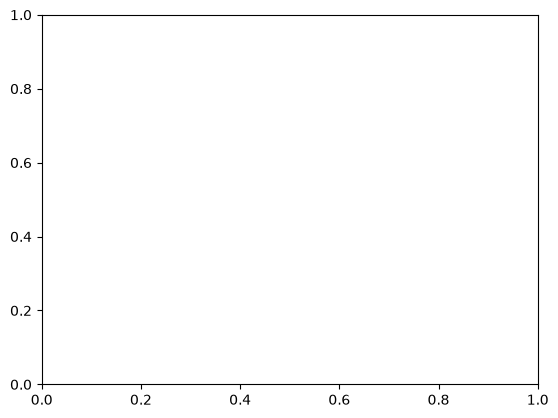

In [34]:
#Variables
rate1 = "1h"
rate2 = "2h"
ThresholdOfChange = 5 # km/s
Alpha = 0.6

# Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# # # xlim = [Start, End]
# ZoomStart = "1996-01-01 00:00"
# ZoomEnd = "1996-01-01 04:00"
# xlim = [ZoomStart, ZoomEnd]
# # ylim = [250, 700]
# ylim = [-65, 700]

fig, ax = plt.subplots()

# dataCut = [[0,1], [2,13], [14,]]

for i in range(len(dataTSConcat)):
    rawData = dataTSConcat[i]
    # rawDataDF = dataTimeSerieses[i][j].to_dataframe()
    # Resample data - Choose a resample rate that seems accurate to changes in data
    resampledRate1 = resampleMean(rawData, rate1)
    resampledRate2 = resampleMean(rawData, rate2)

    # Plot
    PlotVsw(rawData, Columns=["TotVsw"], Label = "Raw data", Color=colour1)
    PlotVsw(resampledRate1, Columns=["TotVsw"], Label = "Resampled: " + rate1, Color=colour2)
    PlotVsw(resampledRate2, Columns=["TotVsw"], Label = "Resampled: " + rate1, Color=colour3)
    # plt.show()
    # plt.xlim([ZoomStart, ZoomEnd])
        


    # Calculate variance of data
    VarRD = rawData.to_dataframe()["TotVsw"].var()
    print( "Variance of raw data = " + str(VarRD))
    VarRate1 = resampledRate1.to_dataframe()["TotVsw"].var()
    print( "Variance of resampled (" + rate1 + ") data = " + str(VarRate1))
    VarRate2 = resampledRate2.to_dataframe()["TotVsw"].var()
    print( "Variance of resampled (" + rate2 + ") data = " + str(VarRate2))

    # Plot "derivative" of data
    DiffRD = rawData.to_dataframe()["TotVsw"].diff()
    DiffRate1 = resampledRate1.to_dataframe()["TotVsw"].diff()
    DiffRate2 = resampledRate2.to_dataframe()["TotVsw"].diff()
    # print(Diff)
    # print(DiffResampled)

    DiffRD.plot(color=colour1)
    DiffRate1.plot(color=colour2)
    DiffRate2.plot(color=colour3)

    # Diff
    # yOrNot = Diff.where(abs(Diff) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
    # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, "steady")
    # # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) != np.nan, "nan") # get nans back
    DiffRDSteadyOrNot = DiffRD.where(abs(DiffRD) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
    DiffRDSteadyOrNot = DiffRDSteadyOrNot.where(abs(DiffRD) > ThresholdOfChange, 1)
    # print(DiffRDSteadyOrNot)

    # DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
    # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, "steady")
    # # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) != np.nan, "nan") # get nans back
    DiffRate1SteadyOrNot = DiffRate1.where(abs(DiffRate1) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
    DiffRate1SteadyOrNot = DiffRate1SteadyOrNot.where(abs(DiffRate1) > ThresholdOfChange, 1)
    # print(DiffRate1SteadyOrNot)

    DiffRate2SteadyOrNot = DiffRate2.where(abs(DiffRate2) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
    DiffRate2SteadyOrNot = DiffRate2SteadyOrNot.where(abs(DiffRate2) > ThresholdOfChange, 1)
    # print(DiffRate2SteadyOrNot)

    # DiffResampledSteadyOrNotAdj = DiffRate2SteadyOrNot*100
    # DiffResampledSteadyOrNotAdj.plot(color="yellow")

    for y in range(len(DiffRate2SteadyOrNot)): # for each start date (and hopefully each steadiness period)
        if DiffRate2SteadyOrNot.values[y] == 0.0 and DiffRate2SteadyOrNot.index[y] != DiffRate2SteadyOrNot.index[-1]:
            plt.axvspan(DiffRate2SteadyOrNot.index[y], DiffRate2SteadyOrNot.index[y+1], color = colour3, alpha = Alpha) # plot vertical highlighted regions to show where the regions of steadiness are
            # plt.axvspan(starts[y], ends[y], ymin = FirstBaseValue-AbsoluteThreshold, ymax = FirstBaseValue+AbsoluteThreshold, color = "green", alpha = 0.1)
    
    plt.ylabel("TotVsw, km/s")
    plt.ylim([-250, 1100])
    plt.show()

    # print( "unique values = " + str(DiffRate1SteadyOrNot.value_counts()))
    print( "Unique values for rate 2 ("+ rate2+") = " + str(DiffRate2SteadyOrNot.value_counts()))
    print("(0 = unsteady, 1 = steady)")